In [1]:
# [셀 1] 라이브러리 임포트 및 실험 설정 (실험 설정만 노트북에서 담당)
from pathlib import Path
import numpy as np
import pandas as pd

# ===분리한 함수 모듈===
from dp_budget import (restart, run_seq_once, run_seq_n, plot_seq_once, plot_seq_dist,
                       run_inv_once, run_inv_n,
                       plot_inv_summary, plot_inv_dist,
                       check_s_rate, check_s_rate_sweep,
                       plot_srate_summary, plot_srate_curve,
                       run_inv_hybrid, plot_hybrid_search, plot_hybrid_consumption,
                       run_hybrid_sweep, summarize_hybrid_sweep,
                       plot_hybrid_sweep_hist, plot_hybrid_ridgeline,
                       plot_hybrid_spread)

In [2]:
# ===코랩용 databench 데이터셋 위치===
# DATA = Path("/content/drive/Othercomputers/내 PC/dp4agent/data/bank_exp.parquet")
# ===코랩용 CardBase 데이터셋 위치===
# DATA = "/content/drive/Othercomputers/내 PC/dp4agent/data/CardBase.csv"        

# ===로컬용 CardBase 데이터셋 위치===
DATA = Path("data/CardBase.csv")
COL  = "Credit_Limit"

# ===클리핑 있을 때 Lower/Upper 바운드===
# L, U = 2000.0, 34000.0
# ===클리핑 없이 진행===
L, U = None, None
EPSILONS = [0.5, 0.75, 1.0, 1.25]

MAXQ      = 500           # 논문 방식이 쿼리를 최대 몇 번까지 반복하는지
N_REPS    = 500           # 반복 시행 횟수 (seed를 바꾸어 개별 시행)
SEED0     = 2026          # i번째 시행은 SEED0 + i를 사용

# ===95% 신뢰구간을 산정(ALPHA)했을 때, 그 '상대폭'이 0.01이하(THRESHOLD)로 5번 유지될 때(STREAK)===
# ===수렴으로 판단하고 정지===
ALPHA     = 0.05          # 1 - 0.95 신뢰수준 95%
THRESHOLD = 0.01          # 신뢰구간 상대폭이 1% 이하가 되면 정지
STREAK    = 5             # 위의 조건이 연속 5회 유지되어야 정지

# ===반복 실험을 위한 랜덤 함수===
rng = np.random.default_rng(0)

# ===결과 저장 디렉터리===
Path("outputs").mkdir(exist_ok=True)

In [ ]:
# restart()

dp_budget.py 다시 로드 완료 — 갱신된 이름 20개:
   check_s_rate, check_s_rate_sweep, plot_hybrid_consumption, plot_hybrid_ridgeline, plot_hybrid_search, plot_hybrid_spread, plot_hybrid_sweep_hist, plot_inv_dist, plot_inv_summary, plot_seq_dist, plot_seq_once, plot_srate_curve, plot_srate_summary, run_hybrid_sweep, run_inv_hybrid, run_inv_n, run_inv_once, run_seq_n, run_seq_once, summarize_hybrid_sweep


<module 'dp_budget' from 'c:\\Users\\seude\\Desktop\\dp4agent\\dp_budget.py'>

In [3]:
# ---------------------------------------------------------------------------
# [한글 폰트 설정] — matplotlib 기본 폰트(DejaVu Sans)는 한글 글리프가 없다.
# OS별로 사용 가능한 한글 폰트를 찾아 rcParams에 등록한다. 실패 시 조용히 넘어감.
# ---------------------------------------------------------------------------
def _setup_korean_font():
    from matplotlib import font_manager as fm
    import matplotlib as mpl

    candidates = [
        ("Windows", ["Malgun Gothic", "Malgun Gothic Regular"]),
        ("Darwin",  ["AppleGothic", "Apple SD Gothic Neo"]),
        ("Linux",   ["NanumGothic", "Noto Sans CJK KR", "Noto Sans KR"]),
    ]
    import platform
    names = []
    for sysname, fonts in candidates:
        if sysname.lower() in platform.system().lower():
            names = fonts
            break
    names += ["NanumGothic", "Noto Sans CJK KR", "Malgun Gothic"]  # 전체 폴백

    installed = {f.name for f in fm.fontManager.ttflist}
    for name in names:
        if name in installed:
            mpl.rcParams["font.family"] = name
            mpl.rcParams["axes.unicode_minus"] = False   # 마이너스 기호 깨짐 방지
            return name

    # 설치 목록에 없으면 파일 경로로 직접 시도 (Windows 맑은고딕 등)
    for path in [r"C:\Windows\Fonts\malgun.ttf",
                 r"C:\Windows\Fonts\malgunbd.ttf",
                 "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"]:
        try:
            fm.fontManager.addfont(path)
            fname = fm.FontProperties(fname=path).get_name()
            mpl.rcParams["font.family"] = fname
            mpl.rcParams["axes.unicode_minus"] = False
            return fname
        except Exception:
            continue
    return None

_KR_FONT = _setup_korean_font()

import matplotlib as plt 
plt.rcParams["axes.unicode_minus"] = False    # 모든 경우에 U+2212 대신 ASCII '-' 사용


In [4]:
# @title
# [셀 2] 데이터 로딩 및 민감도 계산

# ===databench 데이터셋===
# df = pd.read_parquet(DATA)

# ===KCI 논문 속 데이터셋===
df = pd.read_csv(DATA)

x  = df[COL].to_numpy(dtype=float)

n         = len(x)                  # 데이터 수: 500개
true_mean = x.mean()
clip_mean = true_mean

D_PAPER = (x.max() - x.min()) / n     # 논문 방식: 전역 (max - min)/n을 평균 질의에 대한 민감도로 설정

print("==논문과 민감도 비교==")
print(f"n(행 개수)         = {n}")
print(f"데이터 실제 평균값 = {true_mean:,.2f}")

print("======================")
print(f"최대: {x.max()}\t 최소:{x.min()}")
print(f"논문 속 민감도((최대-최소)/N)   = {D_PAPER:,.2f}")


==논문과 민감도 비교==
n(행 개수)         = 500
데이터 실제 평균값 = 252,614.00
최대: 899000.0	 최소:2000.0
논문 속 민감도((최대-최소)/N)   = 1,794.00


In [ ]:
# @title
# [셀 3] KCI 1회 시행 — 함수 정의는 dp_budget.py로 이동

# ===verbose_upto이후부터는 every마다 터미널 출력==
h = run_seq_once(D_PAPER, eps=0.15, true_mean=true_mean, seed=SEED0,
                 threshold=0.10, streak_required=5, maxq=MAXQ,
                 alpha=ALPHA, verbose_upto=5, every=10)


delta=1,794.0000  eps=0.15  b=11,960.0000  threshold=0.1  streak_required=5

k=   1 | resp=  240324.07 | mean= 240324.07 | CI=[         --  ~          -- ] | moe=      nan | relw=     nan | --  | streak=0 
k=   2 | resp=  256540.02 | mean= 248432.04 | CI=[  145410.40 ~   351453.69] | moe=103021.65 | relw= 0.82937 | IN  | streak=0 
k=   3 | resp=  251804.26 | mean= 249556.12 | CI=[  228842.23 ~   270270.00] | moe= 20713.89 | relw= 0.16601 | IN  | streak=0 
k=   4 | resp=  249028.95 | mean= 249424.32 | CI=[  238582.64 ~   260266.00] | moe= 10841.68 | relw= 0.08693 | IN  | streak=1 *
k=   5 | resp=  248515.03 | mean= 249242.47 | CI=[  241898.53 ~   256586.41] | moe=  7343.94 | relw= 0.05893 | IN  | streak=2 **
k=   8 | resp=  240217.88 | mean= 252742.94 | CI=[  243509.92 ~   261975.96] | moe=  9233.02 | relw= 0.07306 | IN  | streak=5 *****

>>> 정지: k=8, eps_total=1.20, 추정=252,742.94, width=9233.02, CI=[243,509.92 ~ 261,975.96]


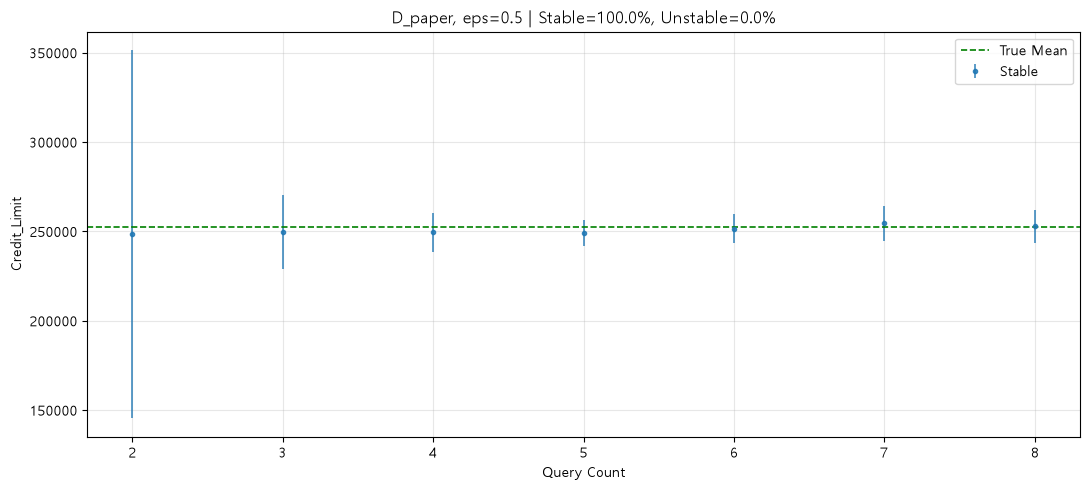

In [8]:
# [셀 4] 1회 시행 궤적 시각화
k_stop = int(h.k.iloc[-1]) if h.streak.iloc[-1] >= 7 else None
plot_seq_once(h, title="D_paper, eps=0.5", true_mean=true_mean,
              k_stop=k_stop, ylabel=COL)


In [9]:
# @title
# [셀 5] KCI n회 반복 — seed를 바꾸어 개별 시행하고 통계 요약 반환
# (벡터화 엔진이라 500회도 약 0.03초)

trials, summary, _ = run_seq_n(true_mean, D_PAPER, eps=0.15,
                               n_reps=N_REPS, seed0=SEED0,
                               threshold=0.10, streak_required=5,
                               maxq=MAXQ, alpha=ALPHA)

print(f"실행 시간: {summary['elapsed_sec']}초")
print(f"수렴률(converged_rate) = {summary['converged_rate']:.3f}  |  절단률(censored_rate) = {summary['censored_rate']:.3f}")
print(f"정지 시점 신뢰구간이 참평균을 포함한 비율(covered_rate) = {summary['covered_rate']:.3f}")
print()
print(f"총예산 eps_total = eps × k_stop")
print(f"  평균   = {summary['eps_total_mean']:.2f}")
print(f"  중앙값 = {summary['eps_total_median']:.2f}")
print(f"  표준편차 = {summary['eps_total_std']:.2f}")
print(f"  IQR    = [{summary['eps_total_q25']:.2f}, {summary['eps_total_q75']:.2f}]")
print(f"  q95    = {summary['eps_total_q95']:.2f}")

trials.head(10)


실행 시간: 0.072초
수렴률(converged_rate) = 1.000  |  절단률(censored_rate) = 0.000
정지 시점 신뢰구간이 참평균을 포함한 비율(covered_rate) = 0.956

총예산 eps_total = eps × k_stop
  평균   = 1.96
  중앙값 = 1.95
  표준편차 = 0.64
  IQR    = [1.50, 2.40]
  q95    = 3.15


,rep,seed,converged,k_stop,k_last,eps_total,relw_stop,covered
0,1,2026,True,8.0,8,1.20,0.073063,True
1,2,2027,True,20.0,20,3.00,0.077176,True
2,3,2028,True,17.0,17,2.55,0.077813,True
3,4,2029,True,12.0,12,1.80,0.062187,True
4,5,2030,True,10.0,10,1.50,0.070852,True
5,6,2031,True,10.0,10,1.50,0.053733,True
6,7,2032,True,16.0,16,2.40,0.071346,True
7,8,2033,True,19.0,19,2.85,0.086181,True
8,9,2034,True,19.0,19,2.85,0.078525,True
9,10,2035,True,11.0,11,1.65,0.064660,True


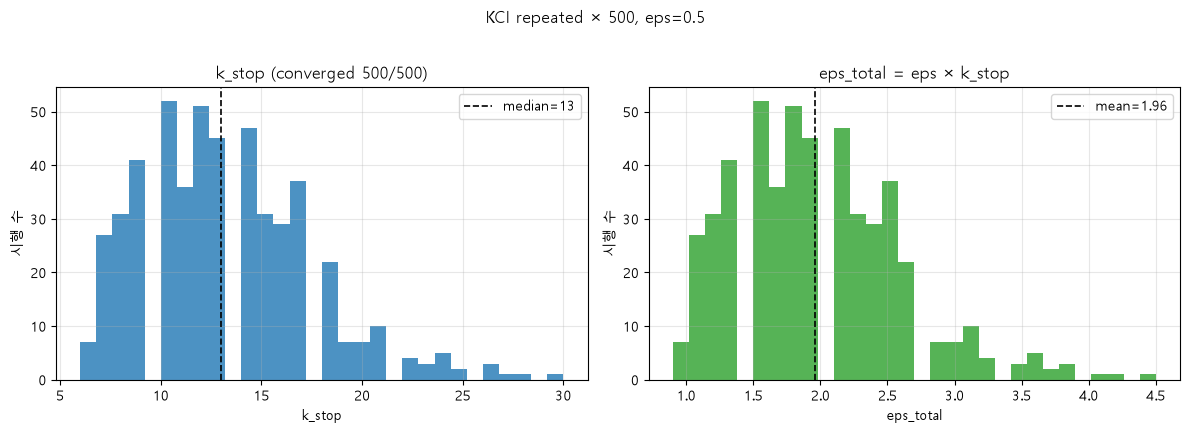

In [10]:
# [셀 6] n회 반복 결과의 분포 시각화 (k_stop / eps_total 히스토그램)
plot_seq_dist(trials, title=f"KCI repeated × {N_REPS}, eps=0.5")


In [ ]:
# @title
# [셀 7] CAPRI형 역산 알고리즘 1회 실행 (step7 #261106 판 → dp_budget.run_inv_once)
# 라운드: 후보 ε_total을 step배씩 올리며, 성공 비율 ≥ 0.95인 첫 라운드에서 합격

# df = run_seq_once(delta=D_PAPER, eps=0.3, true_mean=true_mean, seed=2026,
#                   threshold=0.01, streak_required=3, verbose=True, verbose_upto=5, every=10)

trial_results, round_summary, trajectories, final_eps, info = run_inv_once(
    true_mean=true_mean, delta=D_PAPER, eps=0.3,
    initial_eps_total=35, step=1.03,
    threshold=0.01, streak_required=3,
    success_rate_threshold=0.95, num_runs=100, max_rounds=50,
    maxq=MAXQ, alpha=ALPHA, verbose=True)

print(f"\n기대 소모량 ε = {final_eps}  |  보장 예산 ε = {info['eps_total_guaranteed']}")


[round   1] cand= 35.0000 | k_eval= 116 | success=2/100 (0.020) | pass=False
[round   2] cand= 36.0500 | k_eval= 120 | success=5/100 (0.050) | pass=False
[round   3] cand= 37.1315 | k_eval= 123 | success=7/100 (0.070) | pass=False
[round   4] cand= 38.2454 | k_eval= 127 | success=6/100 (0.060) | pass=False
[round   5] cand= 39.3928 | k_eval= 131 | success=6/100 (0.060) | pass=False
[round   6] cand= 40.5746 | k_eval= 135 | success=12/100 (0.120) | pass=False
[round   7] cand= 41.7918 | k_eval= 139 | success=13/100 (0.130) | pass=False
[round   8] cand= 43.0456 | k_eval= 143 | success=16/100 (0.160) | pass=False
[round   9] cand= 44.3370 | k_eval= 147 | success=14/100 (0.140) | pass=False
[round  10] cand= 45.6671 | k_eval= 152 | success=23/100 (0.230) | pass=False
[round  11] cand= 47.0371 | k_eval= 156 | success=30/100 (0.300) | pass=False
[round  12] cand= 48.4482 | k_eval= 161 | success=41/100 (0.410) | pass=False
[round  13] cand= 49.9016 | k_eval= 166 | success=40/100 (0.400) | pa

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


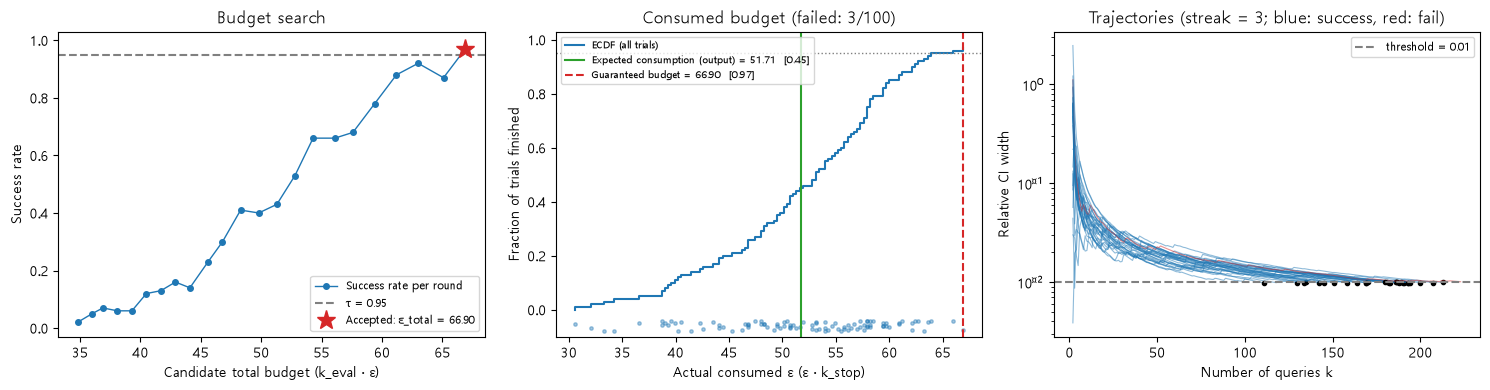

In [25]:
# [셀 8] 역산 1회 결과 시각화 (원본 셀 52의 plot_inverse_summary)
fig = plot_inv_summary(trial_results, round_summary, trajectories, info)


In [ ]:
# @title
# [셀 9] 역산 알고리즘 n회 반복 — seed0을 바꾸어 독립 수행하고 통계 요약 반환
# 역산 1회 = 내부 시행 num_runs번 포함이므로 전체 실행 시간은 n_reps × num_runs에 비례

inv_trials, inv_summary = run_inv_n(
    true_mean=true_mean, delta=D_PAPER, eps=0.1,
    initial_eps_total=5, step=1.03,
    n_reps=20, seed0_base=SEED0,
    threshold=0.05, streak_required=3,
    success_rate_threshold=0.95, num_runs=50, max_rounds=50,
    maxq=MAXQ, alpha=ALPHA, verbose=True)

print(f"\n실행 시간: {inv_summary['elapsed_sec']}초")
print(f"수렴률(converged_rate) = {inv_summary['converged_rate']:.3f}")
print()
print("기대 소모량 final_eps (역산 알고리즘의 출력값 분포)")
print(f"  평균 = {inv_summary['final_eps_mean']:.2f} | 중앙값 = {inv_summary['final_eps_median']:.2f} | 표준편차 = {inv_summary['final_eps_std']:.2f}")
print(f"  IQR = [{inv_summary['final_eps_q25']:.2f}, {inv_summary['final_eps_q75']:.2f}] | q95 = {inv_summary['final_eps_q95']:.2f}")
print()
print("보장 예산 eps_total_guaranteed (합격 라운드의 k_eval × ε)")
print(f"  평균 = {inv_summary['eps_guaranteed_mean']:.2f} | 중앙값 = {inv_summary['eps_guaranteed_median']:.2f}")

inv_trials


In [ ]:
# [셀 10] 역산 n회 반복 결과의 분포 시각화 (기대 소모량 / 보장 예산 히스토그램)
plot_inv_dist(inv_trials, title=f"Inverse × {inv_summary['n_reps']} seeds, eps=0.1")


In [ ]:
# @title
# [셀 11] 총예산을 입력받아 KCI 정지 조건 충족 성공률을 통계적으로 추정
# (step7 "토탈 엡실론을 입력하고 시행 성공률 계산" → dp_budget.check_s_rate)

summary, trials = check_s_rate(
    true_mean=true_mean, delta=D_PAPER, eps=0.1, eps_total=6.1,
    threshold=0.05, streak_required=3,
    num_runs=500, seed0=100_000, maxq=200, alpha=ALPHA)

print(f"총예산 ε_total = {summary['eps_total_input']}  →  질의 상한 k_eval = {summary['k_eval']}"
      + (" (maxq 절단!)" if summary["capped_by_maxq"] else ""))
print(f"수렴(정지 조건 충족) 시행: {summary['n_converged']}/{summary['num_runs']}")
print(f"성공률 = {summary['success_rate']:.3f}  (Wilson 95% CI: [{summary['success_rate_ci95'][0]:.3f}, {summary['success_rate_ci95'][1]:.3f}])")
print(f"수렴 시행의 실제 소모 ε — 평균: {summary['mean_eps_spent_converged']:.2f} / 중앙값: {summary['median_eps_spent_converged']:.2f}")

trials.head(10)


In [ ]:
# [셀 12] 성공률 검정 결과 시각화: ①성공률 게이지+Wilson CI ②소모 예산 ECDF ③정지 시점 분포
plot_srate_summary(summary, trials, title=f"check_s_rate @ eps_total={summary['eps_total_input']}")


In [ ]:
# @title
# [셀 13] 여러 총예산에 대한 수렴(성공) 비율을 한 번의 시뮬레이션으로 계산

sweep = check_s_rate_sweep(
    true_mean=true_mean, delta=D_PAPER, eps=0.1,
    eps_totals=np.arange(2.0, 8.01, 0.5),
    threshold=0.05, streak_required=3,
    num_runs=5000, seed0=100_000, maxq=200, alpha=ALPHA)

sweep.head(13)


In [ ]:
# [셀 14] 총예산 → 성공률 곡선 (Wilson 95% CI 오차막대, maxq 절단 구간 표시)
plot_srate_curve(sweep)


# 새 방법론 - 역산 방식 탐색 효율성 증진

In [31]:
# @title
# [셀 17] 예산 역산 — 지수 탐색 + 이진 탐색 하이브리드 (fresh: 후보 평가마다 새 시드)
# 후보를 eps_total이 아니라 정수 질의 수 k로 직접 진행.
# initial_eps_total / step 입력은 사라지고 k_init / beta로 대체됨.

res_fresh = run_inv_hybrid(true_mean=true_mean, delta=D_PAPER, eps=0.3,
                           threshold=0.01, streak_required=3,
                           tau=0.95, num_runs=100, maxq=MAXQ,
                           k_init=2, beta=2, seed0=SEED0, alpha=ALPHA,
                           seed_policy="fresh")

print(f"status = {res_fresh['status']} | k_min = {res_fresh['k_min']}"
      f" | 보장 예산 ε = {res_fresh['eps_guaranteed']:.1f}"
      f" | 기대 소모량 ε = {res_fresh['eps_expected']:.2f}")
print(f"후보 평가 {len(res_fresh['evals'])}회, 소모 질의 {res_fresh['queries_used']:,}개")
res_fresh["evals"]   # 탐색 과정: 지수 단계(2배씩) → 이진 단계(중앙값) 순서로 기록


status = converged | k_min = 225 | 보장 예산 ε = 67.5 | 기대 소모량 ε = 51.51
후보 평가 15회, 소모 질의 207,700개


,round,k,success_rate,passed,seed0_eval
0,1,2,0.00,False,1002029
1,2,4,0.01,False,2002032
2,3,8,0.00,False,3002035
3,4,16,0.00,False,4002038
4,5,32,0.00,False,5002041
5,6,64,0.00,False,6002044
6,7,128,0.06,False,7002047
7,8,256,1.00,True,8002050
8,9,192,0.77,False,9002053
9,10,224,0.93,False,10002056


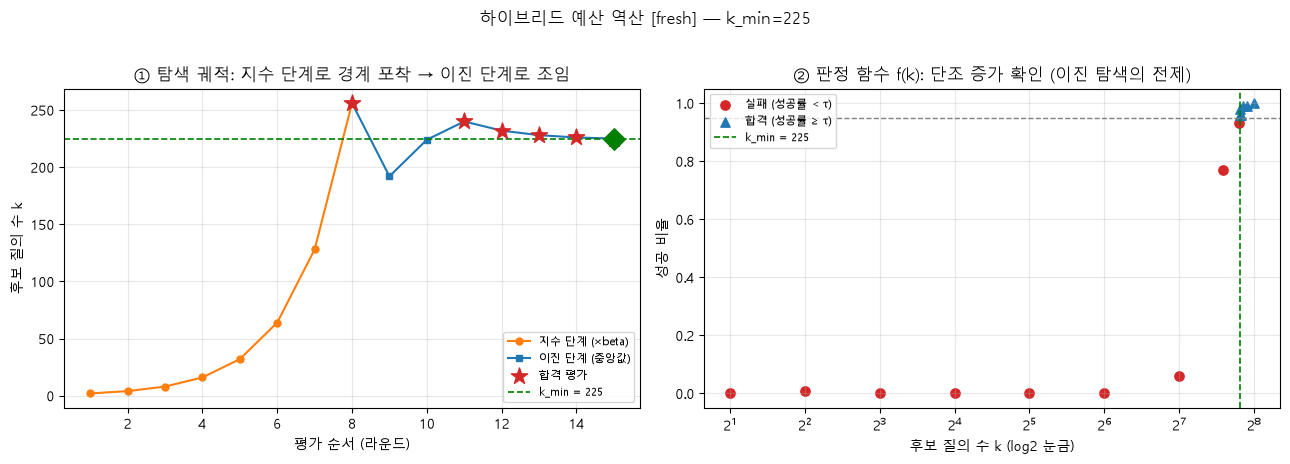

In [32]:
# [셀 20] 하이브리드 탐색 과정 시각화 (fresh 정책 실행 직후)
# ① 탐색 궤적: 지수 단계(주황)로 경계 포착 → 이진 단계(파랑)로 중앙값 조이기
# ② 판정 함수: 기록된 (k, 성공률) 점들이 단조인지 확인 — fresh는 경계 노이즈가 보일 수 있음
plot_hybrid_search(res_fresh, title=f"하이브리드 예산 역산 [fresh] — k_min={res_fresh['k_min']}");


In [5]:
# @title
# [셀 18] 같은 탐색, fixed 정책 — 시행 시드를 탐색 전체에서 고정
# 판정이 결정적(같은 입력 → 같은 결과)이고 f가 정확히 단조가 됨.

res_fixed = run_inv_hybrid(true_mean=true_mean, delta=D_PAPER, eps=0.15,
                           threshold=0.10, streak_required=5,
                           tau=0.75, num_runs=500, maxq=MAXQ,
                           k_init=2, beta=2, seed0=SEED0, alpha=ALPHA,
                           seed_policy="fixed")

print(f"status = {res_fixed['status']} | k_min = {res_fixed['k_min']}"
      f" | 보장 예산 ε = {res_fixed['eps_guaranteed']:.1f}"
      f" | 기대 소모량 ε = {res_fixed['eps_expected']:.2f}")
print(f"후보 평가 {len(res_fixed['evals'])}회, 소모 질의 {res_fixed['queries_used']:,}개")
res_fixed["evals"]


status = converged | k_min = 16 | 보장 예산 ε = 2.4 | 기대 소모량 ε = 1.72
후보 평가 7회, 소모 질의 35,500개


,round,k,success_rate,passed,seed0_eval
0,1,2,0.000,False,2026
1,2,4,0.000,False,2026
2,3,8,0.130,False,2026
3,4,16,0.794,True,2026
4,5,12,0.490,False,2026
5,6,14,0.674,False,2026
6,7,15,0.736,False,2026


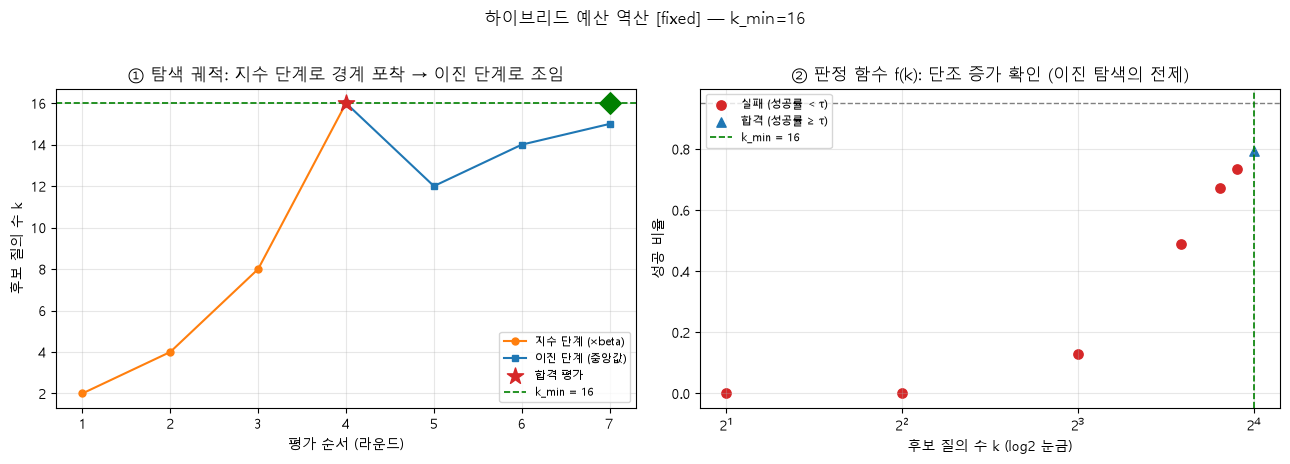

In [6]:
# [셀 21] fixed 정책도 같은 그림 — 판정이 결정적이라 ② 패널이 완벽한 단조로 나옴
plot_hybrid_search(res_fixed, title=f"하이브리드 예산 역산 [fixed] — k_min={res_fixed['k_min']}");


In [11]:
# [셀 19] 정책 비교 요약 — fresh(독립 평가) vs fixed(결정적) vs 기존 run_inv_once
print(f"hybrid(fresh): k_min={res_fresh['k_min']}  소모 질의={res_fresh['queries_used']:,}")
print(f"hybrid(fixed): k_min={res_fixed['k_min']}  소모 질의={res_fixed['queries_used']:,}")
if 'info' in dir() and info.get('status') == 'converged':
    print(f"기존 run_inv_once: 보장 예산={info['eps_total_guaranteed']}  (k 환산 ≈ {info['eps_total_guaranteed']/0.1:.0f})")


hybrid(fresh): k_min=225  소모 질의=207,700
hybrid(fixed): k_min=215  소모 질의=199,100


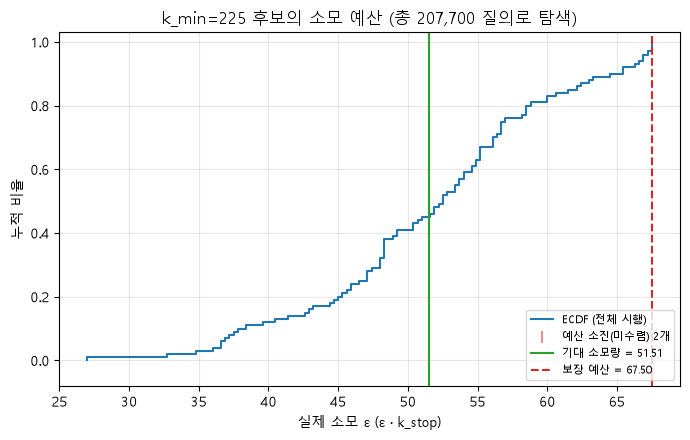

In [12]:
# [셀 22] 최종 후보(k_min)의 소모 예산 분포 — 기대 소모량 vs 보장 예산
plot_hybrid_consumption(res_fresh);


In [ ]:
# @title
# [셀 23] 하이브리드 역산(fixed)을 num_runs × 시드 격자에서 수행
# 원본 run_inverse_seed_sweep(§8)의 목적 그대로:
#   (1) 시드를 바꿨을 때 k_min이 얼마나 움직이는가 (재현성)
#   (2) num_runs를 키우면 그 움직임이 줄어드는가 (판정 안정성)

sweep_df = run_hybrid_sweep(
    true_mean=true_mean, delta=D_PAPER, eps=0.1,
    threshold=0.05, streak_required=3,
    num_runs_list=(1, 10, 25, 50, 100, 200, 300, 500), n_seeds=20,
    tau=0.95, maxq=MAXQ, k_init=2, beta=2,
    seed0_base=SEED0, alpha=ALPHA)

sweep_df


,num_runs,seed_idx,seed0,status,k_min,eps_guaranteed,eps_expected,n_evals,queries_used
0,1,1,2026,converged,42,4.2,4.200000,11,341
1,1,2,10002045,converged,48,4.8,4.800000,11,351
2,1,3,20002064,converged,68,6.8,6.800000,13,703
3,1,4,30002083,converged,58,5.8,5.800000,11,405
4,1,5,40002102,converged,68,6.8,6.800000,13,703
...,...,...,...,...,...,...,...,...,...
155,500,16,150002311,converged,93,9.3,5.935579,13,398500
156,500,17,160002330,converged,95,9.5,6.024528,13,399500
157,500,18,170002349,converged,93,9.3,6.164092,13,398500
158,500,19,180002368,converged,92,9.2,6.194340,13,395500


In [18]:
# [셀 24] num_runs별 보장 예산(ε) 흩어짐 요약 — eps_guaranteed_std / eps_guaranteed_iqr이
# num_runs와 함께 줄어들면 "판정 시행 수를 키울수록 예산 추정이 안정된다"는 증거
hybrid_summary = summarize_hybrid_sweep(sweep_df)
hybrid_summary


,num_runs,eps_guaranteed_n,eps_guaranteed_median,eps_guaranteed_mean,eps_guaranteed_std,eps_guaranteed_min,eps_guaranteed_max,eps_guaranteed_iqr,k_min_median,k_min_std,converged_rate,queries_mean
0,1,20,6.25,5.890,2.275938,0.4,10.7,2.450,62.5,22.759382,1.0,523.3
1,10,20,8.85,8.925,1.229409,6.7,10.8,1.750,88.5,12.294094,1.0,7934.0
2,25,20,9.05,8.970,0.789470,7.7,10.5,1.150,90.5,7.894702,1.0,19835.0
3,50,20,9.15,9.160,0.573448,8.3,10.3,0.800,91.5,5.734476,1.0,39930.0
4,100,20,9.10,9.065,0.406882,8.3,9.8,0.450,91.0,4.068816,1.0,79440.0
5,200,20,9.15,9.205,0.291051,8.8,9.9,0.425,91.5,2.910507,1.0,159780.0
6,300,20,9.30,9.215,0.215883,8.7,9.6,0.225,93.0,2.158825,1.0,237780.0
7,500,20,9.25,9.235,0.187153,8.7,9.5,0.125,92.5,1.871532,1.0,396600.0


In [ ]:
# # [셀 25] 스윕 시각화
# # 왼쪽부터: 각 num_runs 패널에서 시드별 k_min 점 (중앙값 점선) — 흩어짐 비교
# # 히트맵: 시드 × num_runs 격자 — 특정 시드만 이상하게 튀는지 한눈에 확인
# plot_hybrid_sweep_beeswarm(sweep_df)
# plot_hybrid_sweep_heatmap(sweep_df)


(<Figure size 640x370 with 1 Axes>,
 <Axes: title={'center': 'num_runs에 따른 보장 예산의 흩어짐'}, xlabel='num_runs (로그축)', ylabel='보장 예산의 흩어짐 (로그축)'>)

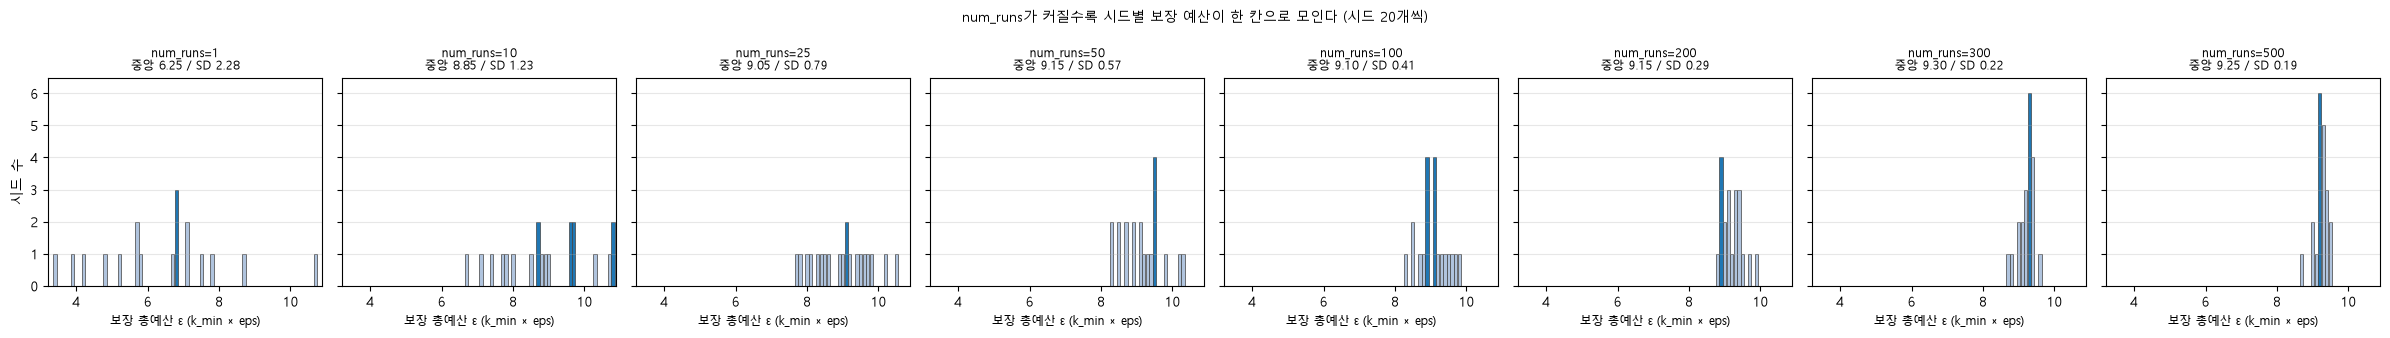

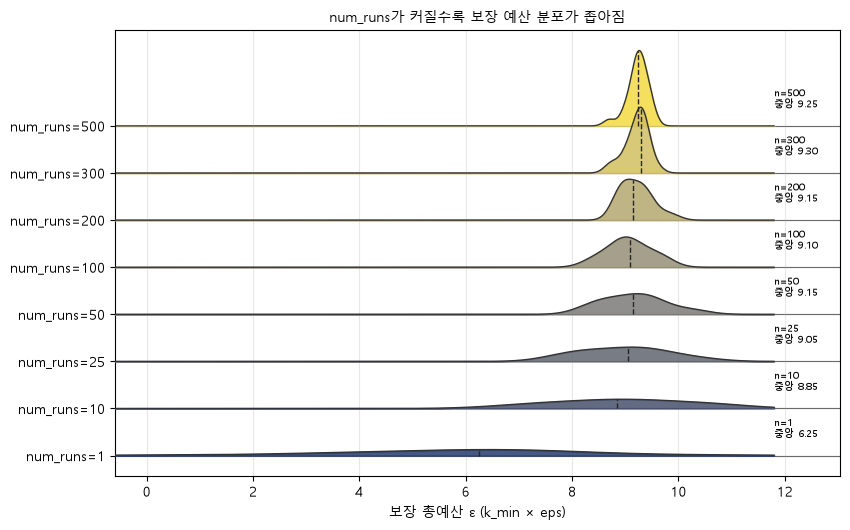

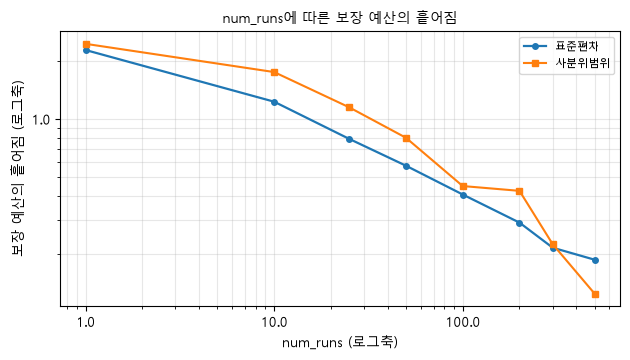

In [19]:
# [셀 25] 스윕 시각화 — 보장 예산(ε) 축
plot_hybrid_sweep_hist(sweep_df);
plot_hybrid_ridgeline(sweep_df)
plot_hybrid_spread(hybrid_summary)


In [5]:
# [셀 11] 총예산을 입력받아 KCI 정지 조건 충족 성공률을 통계적으로 추정
# (step7 "토탈 엡실론을 입력하고 시행 성공률 계산" → dp_budget.check_s_rate)

summary, trials = check_s_rate(
    true_mean=true_mean, delta=D_PAPER, eps=0.3, eps_total=66.3,
    threshold=0.01, streak_required=3,
    num_runs=500, seed0=SEED0, maxq=MAXQ, alpha=ALPHA)

print(f"총예산 ε_total = {summary['eps_total_input']}  →  질의 상한 k_eval = {summary['k_eval']}"
      + (" (maxq 절단!)" if summary["capped_by_maxq"] else ""))
print(f"수렴(정지 조건 충족) 시행: {summary['n_converged']}/{summary['num_runs']}")
print(f"성공률 = {summary['success_rate']:.3f}  (Wilson 95% CI: [{summary['success_rate_ci95'][0]:.3f}, {summary['success_rate_ci95'][1]:.3f}])")
print(f"수렴 시행의 실제 소모 ε — 평균: {summary['mean_eps_spent_converged']:.2f} / 중앙값: {summary['median_eps_spent_converged']:.2f}")

trials.head(10)


총예산 ε_total = 66.3  →  질의 상한 k_eval = 221
수렴(정지 조건 충족) 시행: 475/500
성공률 = 0.950  (Wilson 95% CI: [0.927, 0.966])
수렴 시행의 실제 소모 ε — 평균: 50.63 / 중앙값: 51.30


,trial,seed,converged,stop_k,eps_spent,final_relw,final_mean
0,1,2026,True,137.0,41.1,0.009840,252783.896360
1,2,2027,True,179.0,53.7,0.009892,251996.075363
2,3,2028,True,194.0,58.2,0.009902,251792.606410
3,4,2029,True,196.0,58.8,0.009920,253099.043712
4,5,2030,True,189.0,56.7,0.009867,251909.702651
5,6,2031,True,185.0,55.5,0.009890,252435.861542
6,7,2032,True,128.0,38.4,0.009860,252967.643142
7,8,2033,True,199.0,59.7,0.009938,253018.886688
8,9,2034,False,NaN,66.3,0.010076,252029.155594
9,10,2035,True,151.0,45.3,0.009854,252605.995046
